In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error


In [ ]:
df = pd.read_csv(r"pakistan_tech_jobs_final.csv")
df.drop('job_description', inplace=True, axis=1)
df['education'] = df['education'].fillna(df['education'].mode()[0])
df['job_title'] = df['job_title'].fillna(df['job_title'].mode()[0])
df.head()

,job_id,job_title,company,required_skills,city,province,experience_min,experience_max,education,employment_type,work_mode,salary_min,salary_max,posted_date,job_category,source_website
0,1001,Senior Full-Stack & AI Engineer,Jack Mitchel,"Python, JavaScript, TypeScript, Node.js, React...",Karachi,Sindh,5.0,8.0,Bachelor's,Full-time,Remote,560000.0,840000.0,2026-10-30,Data Science / AI / ML,Bano Qabil Jobs
1,1002,"Front end developer, UI/UX Designing",Sharp Mind,"HTML, CSS, Java, UI/UX Design",Lahore,Punjab,2.0,5.0,Bachelor's,Full-time,On-site,80000.0,110000.0,2026-10-30,Web Development,Bano Qabil Jobs
2,1003,MACHINE LEARNING ENGINNER,MUHAMMAD AFNAN,"Core ML Expertise, Solid Programming (Python, ...",Lahore,Punjab,2.0,5.0,Bachelor's,Full-time,On-site,60000.0,100000.0,2026-10-30,Data Science / AI / ML,Bano Qabil Jobs
3,1004,Frontend Developer (React + Next.js),VertexInvo,"React, Next.js",Karachi,Sindh,2.0,5.0,Bachelor's,Full-time,On-site,50000.0,60000.0,2026-10-30,Web Development,Bano Qabil Jobs
4,1005,Mobile App Developer (Flutter),Mohsin Shiekh,"Python, JavaScript, SQL, Git",Karachi,Sindh,0.0,2.0,Bachelor's,Full-time,Remote,40000.0,59998.0,2026-10-30,Mobile Development,Bano Qabil Jobs


In [ ]:
cols_for_model = ['experience_min', 'city', 'job_category', 'work_mode', 'education', 'experience_max', 'required_skills']
reg_df = df[cols_for_model].copy()
reg_df.head()

,experience_min,city,job_category,work_mode,education,experience_max,required_skills
0,5.0,Karachi,Data Science / AI / ML,Remote,Bachelor's,8.0,"Python, JavaScript, TypeScript, Node.js, React..."
1,2.0,Lahore,Web Development,On-site,Bachelor's,5.0,"HTML, CSS, Java, UI/UX Design"
2,2.0,Lahore,Data Science / AI / ML,On-site,Bachelor's,5.0,"Core ML Expertise, Solid Programming (Python, ..."
3,2.0,Karachi,Web Development,On-site,Bachelor's,5.0,"React, Next.js"
4,0.0,Karachi,Mobile Development,Remote,Bachelor's,2.0,"Python, JavaScript, SQL, Git"


In [ ]:
reg_df['experience'] = (reg_df['experience_min'] + reg_df['experience_max']) / 2
reg_df['num_skills'] = reg_df['required_skills'].fillna('').apply(lambda s: len([x for x in str(s).split(',') if x.strip()]))
reg_df['education'] = reg_df['education'].replace({"Master's": 1, "Bachelor's": 0}).astype(int)
reg_df.head()

,experience_min,city,job_category,work_mode,education,experience_max,required_skills,experience,num_skills
0,5.0,Karachi,Data Science / AI / ML,Remote,0,8.0,"Python, JavaScript, TypeScript, Node.js, React...",6.5,6
1,2.0,Lahore,Web Development,On-site,0,5.0,"HTML, CSS, Java, UI/UX Design",3.5,4
2,2.0,Lahore,Data Science / AI / ML,On-site,0,5.0,"Core ML Expertise, Solid Programming (Python, ...",3.5,5
3,2.0,Karachi,Web Development,On-site,0,5.0,"React, Next.js",3.5,2
4,0.0,Karachi,Mobile Development,Remote,0,2.0,"Python, JavaScript, SQL, Git",1.0,4


In [ ]:
# Using sklearn MinMaxScaler for feature scaling
scaler_mm = MinMaxScaler()
exp_norm = scaler_mm.fit_transform(reg_df[['experience']]).flatten()
skills_norm = scaler_mm.fit_transform(reg_df[['num_skills']]).flatten()
edu_norm = scaler_mm.fit_transform(reg_df[['education']]).flatten()
# Formula for likelihood: 50% Experience, 35% Number of Skills, 15% Education
reg_df['likelihood'] = np.round((exp_norm * 50) + (skills_norm * 35) + (edu_norm * 15), 2)
reg_df[['experience', 'num_skills', 'education', 'likelihood']].head(10)

,experience,num_skills,education,likelihood
0,6.5,6,0,65.00
1,3.5,4,0,35.00
2,3.5,5,0,40.00
3,3.5,2,0,25.00
4,1.0,4,0,18.33
5,1.0,4,0,18.33
6,1.0,4,0,18.33
7,1.0,4,0,18.33
8,1.0,4,0,18.33
9,1.0,5,0,23.33


In [ ]:
senior_kw = ['senior', 'sr', 'lead', 'principal', 'architect', 'head', 'manager', 'director']
reg_df['is_senior'] = df['job_title'].fillna('').str.lower().apply(lambda t: int(any(k in t for k in senior_kw)))
high_skills = ['aws', 'cloud', 'devops', 'docker', 'kubernetes', 'python', 'machine learning', 'react']
reg_df['has_high_skill'] = reg_df['required_skills'].fillna('').str.lower().apply(lambda s: int(any(k in s for k in high_skills)))
reg_df.head()

,experience_min,city,job_category,work_mode,education,experience_max,required_skills,experience,num_skills,likelihood,is_senior,has_high_skill
0,5.0,Karachi,Data Science / AI / ML,Remote,0,8.0,"Python, JavaScript, TypeScript, Node.js, React...",6.5,6,65.00,1,1
1,2.0,Lahore,Web Development,On-site,0,5.0,"HTML, CSS, Java, UI/UX Design",3.5,4,35.00,0,0
2,2.0,Lahore,Data Science / AI / ML,On-site,0,5.0,"Core ML Expertise, Solid Programming (Python, ...",3.5,5,40.00,0,1
3,2.0,Karachi,Web Development,On-site,0,5.0,"React, Next.js",3.5,2,25.00,0,1
4,0.0,Karachi,Mobile Development,Remote,0,2.0,"Python, JavaScript, SQL, Git",1.0,4,18.33,0,1


In [ ]:
top_cities = ['Karachi', 'Lahore', 'Islamabad', 'Rawalpindi']
reg_df['city_tier'] = reg_df['city'].apply(lambda x: x if x in top_cities else 'Other')
reg_df = pd.get_dummies(reg_df, drop_first=True, columns=['work_mode', 'city_tier', 'job_category'], dtype=int)
reg_df.drop(columns=['city', 'required_skills', 'experience_min', 'experience_max'], inplace=True)
reg_df.head()

,education,experience,num_skills,likelihood,is_senior,has_high_skill,work_mode_On-site,work_mode_Remote,city_tier_Karachi,city_tier_Lahore,city_tier_Other,city_tier_Rawalpindi,job_category_Cybersecurity,job_category_Data Science / AI / ML,job_category_Mobile Development,job_category_QA / Testing,job_category_Software Development,job_category_Web Development
0,0,6.5,6,65.00,1,1,0,1,1,0,0,0,0,1,0,0,0,0
1,0,3.5,4,35.00,0,0,1,0,0,1,0,0,0,0,0,0,0,1
2,0,3.5,5,40.00,0,1,1,0,0,1,0,0,0,1,0,0,0,0
3,0,3.5,2,25.00,0,1,1,0,1,0,0,0,0,0,0,0,0,1
4,0,1.0,4,18.33,0,1,0,1,1,0,0,0,0,0,1,0,0,0


In [8]:
X = reg_df.drop(columns=['likelihood'])
y = reg_df['likelihood']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print("X_train shape:", X_train_scaled.shape)
print("X_test shape:", X_test_scaled.shape)

X_train shape: (1607, 17)
X_test shape: (536, 17)


In [ ]:
mlp = MLPRegressor(hidden_layer_sizes=(64, 32),activation='relu',solver='adam',max_iter=300,random_state=42, early_stopping=True)
mlp.fit(X_train_scaled, y_train)
y_pred = mlp.predict(X_test_scaled)
y_pred_train = mlp.predict(X_train_scaled)
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
print(f"Test R2 Score: {r2:.4f}")
print(f"Train R2 Score: {r2_score(y_train, y_pred_train):.4f}")
print(f"MAE: {mae:.4f}")
print(f"RMSE: {rmse:.4f}")


Test R2 Score: 0.9957
Train R2 Score: 0.9972
MAE: 0.8518
RMSE: 1.1540


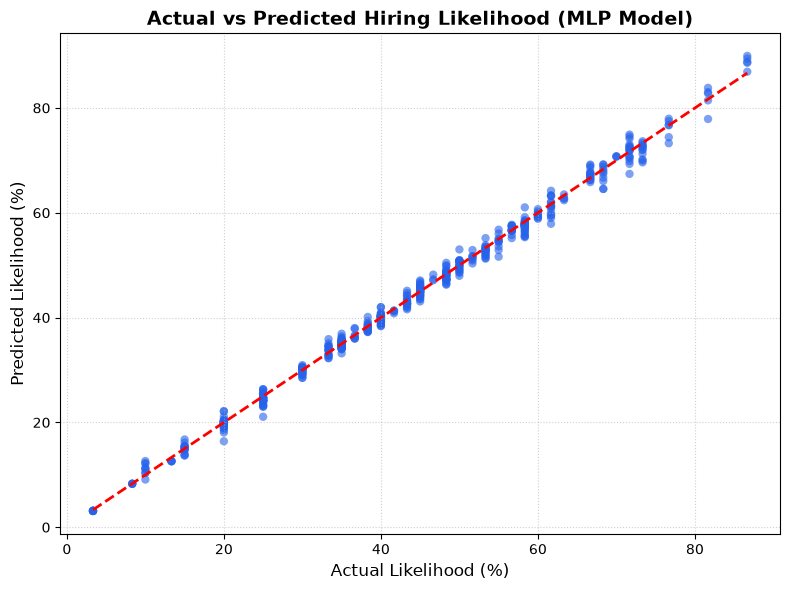

In [10]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.6, color='#2563EB', edgecolors='none')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.title('Actual vs Predicted Hiring Likelihood (MLP Model)', fontsize=14, fontweight='bold')
plt.xlabel('Actual Likelihood (%)', fontsize=12)
plt.ylabel('Predicted Likelihood (%)', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()


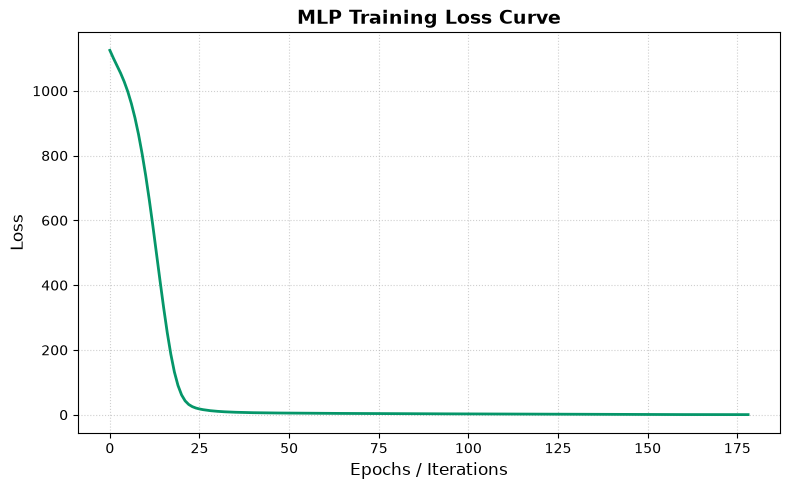

In [11]:
plt.figure(figsize=(8, 5))
plt.plot(mlp.loss_curve_, color='#059669', lw=2)
plt.title('MLP Training Loss Curve', fontsize=14, fontweight='bold')
plt.xlabel('Epochs / Iterations', fontsize=12)
plt.ylabel('Loss', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()
